# Week 5: Vehicle Orientation Estimation Using the Radon Transform
This code estimates the main axis orientation of a cropped vehicle image using Canny edge detection and the Radon transform. It compares the estimated axis with the ground-truth orientation.

1. Load Libraries

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from skimage.feature import canny
from skimage.transform import radon

2. Display cropped image

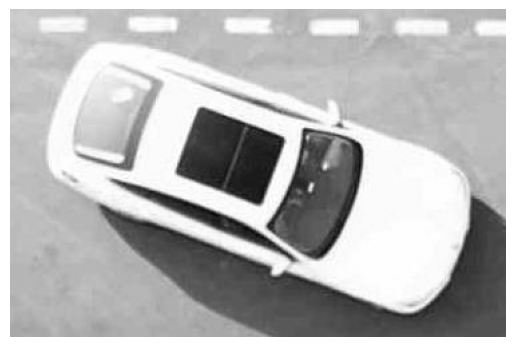

In [ ]:
image_path = "v1_Sedan_17.1deg.jpg"
ground_truth = 17.1
sobel_estimate = 11.0
image = cv2.imread(image_path)
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(gray, cmap="gray")
plt.axis("off")
plt.show()

3. Detect Vehicle Edges Using Canny

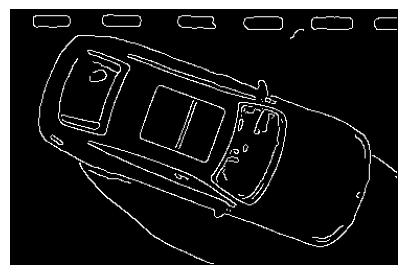

In [ ]:
edges = canny(gray.astype(float) / 255.0, sigma=1.0)

plt.figure(figsize=(5, 5))
plt.imshow(edges, cmap="gray")
plt.axis("off")
plt.show()

4. Apply the Radon Transform

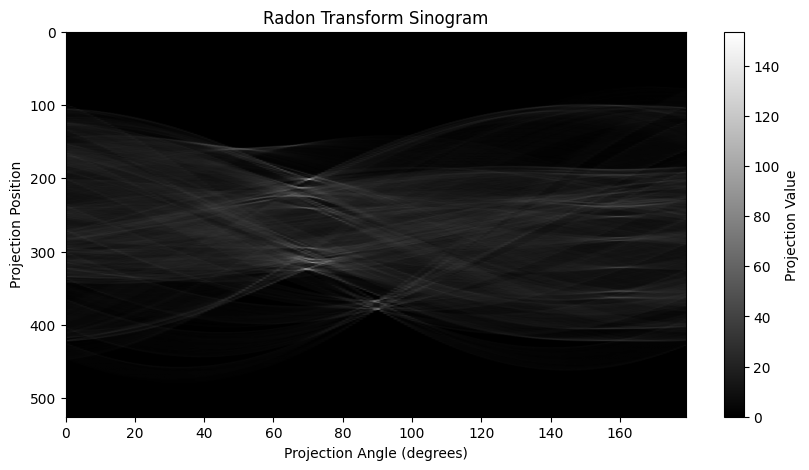

In [ ]:
theta = np.arange(0, 180, 1)

sinogram = radon(
    edges.astype(float),
    theta=theta,
    circle=False
)

plt.figure(figsize=(10, 5))
plt.imshow(
    sinogram,
    cmap="gray",
    aspect="auto",
    extent=[theta[0], theta[-1], sinogram.shape[0], 0]
)
plt.xlabel("Projection Angle (degrees)")
plt.ylabel("Projection Position")
plt.title("Radon Transform Sinogram")
plt.colorbar(label="Projection Value")
plt.show()

5. Estimate the Vehicle's Main Axis Orientation

In [ ]:
projection_variance = np.var(sinogram, axis=0)

best_projection_angle = theta[np.argmax(projection_variance)]

radon_axis_angle = (best_projection_angle + 90) % 180

def convert_to_0_90(angle):
    angle = angle % 180
    if angle > 90:
        angle = 180 - angle
    return angle

radon_estimate = convert_to_0_90(radon_axis_angle)
ground_truth_converted = convert_to_0_90(ground_truth)

print("Best Radon Projection Angle:", best_projection_angle, "degrees")
print("Radon Estimated Axis:", round(radon_estimate, 2), "degrees")
print("Ground Truth Axis:", round(ground_truth_converted, 2), "degrees")

Best Radon Projection Angle: 70 degrees
Radon Estimated Axis: 20 degrees
Ground Truth Axis: 17.1 degrees


6. Compare Sobel and Radon Estimate with Ground Truth

In [ ]:
radon_error = abs(radon_estimate - ground_truth_converted)
sobel_error = abs(sobel_estimate - ground_truth_converted)

print("Ground Truth Angle:", round(ground_truth_converted, 2))
print("Sobel Estimated Angle:", round(sobel_estimate, 2))
print("Sobel Error:", round(sobel_error, 2))
print("Radon Estimated Angle:", round(radon_estimate, 2))
print("Radon Error:", round(radon_error, 2))

Ground Truth Angle: 17.1
Sobel Estimated Angle: 11.0
Sobel Error: 6.1
Radon Estimated Angle: 20
Radon Error: 2.9
